# **Кейс: оценка успешности проведения A/B теста**

**Цель проекта:** Оценить успешность проведённого A/B-теста по внедрению новой механики геймификации — системы достижений за регулярное решение задач — на образовательной платформе. На основе статистического анализа необходимо принять аргументированное бизнес-решение: раскатить новую функцию на всех пользователей, отправить её на доработку или отказаться от неё.

**Описание проекта:** Продуктовая команда EdTech-компании выдвинула гипотезу: если добавить в личный кабинет ученика элементы геймификации, то конверсия в полное прохождение курса (Completion Rate) и метрики удержания (Retention 7 и 14 дня) статистически значимо вырастут.

Для проверки гипотезы был запущен A/B-тест. Пользователи были случайным образом разделены на две группы: группа A — контрольная, со старым интерфейсом; группа B — тестовая, с интерфейсом, в который добавлена геймификация. Эксперимент длился 3 недели.

**Выаолнила:** Крайних Анастасия

## Этап 1: Загрузка и подготовка данных 

In [2]:
import pandas as pd 
import statsmodels as stas
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
groups = pd.read_csv('data_vk/ab_test_users_groups.csv')
events = pd.read_csv('data_vk/ab_test_events.csv')

In [71]:
groups.head(3)

,user_id,group,signup_date,grade
0,U300000,B,2026-03-09,5
1,U300001,B,2025-09-07,9
2,U300002,B,2026-01-11,9


In [72]:
groups.info()

<class 'pandas.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      6008 non-null   str  
 1   group        6008 non-null   str  
 2   signup_date  6008 non-null   str  
 3   grade        6008 non-null   int64
dtypes: int64(1), str(3)
memory usage: 293.5 KB


In [73]:
groups.describe()

,grade
count,6008.000000
mean,7.962051
std,1.998141
min,5.000000
25%,6.000000
50%,8.000000
75%,10.000000
max,11.000000


In [74]:
groups['signup_date'] = pd.to_datetime(groups['signup_date'])

In [75]:
groups.isna().sum()

user_id        0
group          0
signup_date    0
grade          0
dtype: int64

In [76]:
groups['user_id'].duplicated().sum()

np.int64(8)

In [77]:
groups[groups['user_id'] == 'U300357']

,user_id,group,signup_date,grade
357,U300357,A,2026-03-19,9
6000,U300357,B,2026-03-19,9


In [78]:
duplicates = groups[
    groups['user_id'].duplicated(keep=False)
].sort_values('user_id')

duplicates

,user_id,group,signup_date,grade
357,U300357,A,2026-03-19,9
6000,U300357,B,2026-03-19,9
460,U300460,B,2025-08-12,6
6001,U300460,A,2025-08-12,6
920,U300920,B,2025-04-09,10
6002,U300920,A,2025-04-09,10
1014,U301014,A,2026-03-28,10
6003,U301014,B,2026-03-28,10
1087,U301087,B,2025-06-27,10
6004,U301087,A,2025-06-27,10


In [79]:
groups['group'].value_counts()

group
A    3005
B    3003
Name: count, dtype: int64

In [80]:
groups = groups.drop_duplicates('user_id', keep=False)

In [81]:
groups['group'].value_counts()

group
A    2997
B    2995
Name: count, dtype: int64

In [82]:
groups['grade'].value_counts()

grade
6     912
8     886
5     862
10    848
7     840
11    834
9     810
Name: count, dtype: int64

In [83]:
groups['signup_date'].agg(['min', 'max'])

min   2025-03-31
max   2026-04-04
Name: signup_date, dtype: datetime64[us]

In [84]:
events.head(3)

,user_id,timestamp,event_type
0,U300281,2026-05-04 00:06:44,homework_completed
1,U300733,2026-05-04 00:19:56,homework_completed
2,U304499,2026-05-04 00:22:07,login


In [85]:
events.info()

<class 'pandas.DataFrame'>
RangeIndex: 179330 entries, 0 to 179329
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   user_id     179330 non-null  str  
 1   timestamp   179330 non-null  str  
 2   event_type  179330 non-null  str  
dtypes: str(3)
memory usage: 10.5 MB


In [86]:
events.describe()

,user_id,timestamp,event_type
count,179330,179330,179330
unique,6000,17284,5
top,U303729,2026-05-11 18:00:00,login
freq,842,4549,75552


In [87]:
events['timestamp'] = pd.to_datetime(events['timestamp'])

In [88]:
events[events.duplicated(keep = False)]

,user_id,timestamp,event_type
3,U304266,2026-05-04 00:23:42,homework_started
4,U304266,2026-05-04 00:23:42,homework_started
86876,U304499,2026-05-14 13:49:54,homework_started
86877,U304499,2026-05-14 13:49:54,homework_started


In [92]:
events = events.drop_duplicates()

In [93]:
events.isna().sum()

user_id       0
timestamp     0
event_type    0
dtype: int64

In [94]:
print(pd.unique(events['event_type']))
print(events['timestamp'].agg(['min', 'max']))

<ArrowStringArray>
['homework_completed',              'login',   'homework_started',
    'return_visit_d7',   'return_visit_d14']
Length: 5, dtype: str
min   2026-05-04 00:06:44
max   2026-05-24 23:55:43
Name: timestamp, dtype: datetime64[us]


In [95]:
events['event_type'].value_counts()

event_type
login                 75552
homework_started      68315
homework_completed    28995
return_visit_d7        4519
return_visit_d14       1947
Name: count, dtype: int64

In [119]:
users_events = events.groupby('user_id')['event_type'].count()
print(f"Количество событий на пользователя:\n{users_events.agg(['min', 'max'])}")
print(f"Среднее количество событий на пользователя: {users_events.mean()}")
print(f"Медиана: {users_events.median()}")
print(f"75 прoцентиль: {users_events.quantile(0.75)}")
print(f"90 прoцентиль: {users_events.quantile(0.9)}")
print(f"99 прoцентиль: {users_events.quantile(0.99)}")

Количество событий на пользователя:
min      6
max    842
Name: event_type, dtype: int64
Среднее количество событий на пользователя: 29.888
Медиана: 28.0
75 прoцентиль: 33.0
90 прoцентиль: 37.0
99 прoцентиль: 45.01000000000022


In [123]:
users_events.sort_values(ascending = False).head(20)

user_id
U303729    842
U304167    829
U305378    793
U302840    790
U304266    780
U300573    771
U300733    770
U302379    765
U300281    760
U300158    738
U304499    729
U303438    711
U300628     52
U303387     51
U301601     51
U300180     50
U304916     49
U304885     49
U301577     49
U300388     49
Name: event_type, dtype: int64

In [129]:
events[events['user_id']== 'U303729'].groupby('event_type').count()

,user_id,timestamp
event_type,,
homework_completed,285,285
homework_started,308,308
login,248,248
return_visit_d14,1,1


In [139]:
user_events = events[events['user_id'] == 'U303729'].sort_values('timestamp').copy()
user_events['interval'] = user_events['timestamp'].diff()
user_events[['timestamp', 'event_type', 'interval']]
user_events['interval_min'] = user_events['interval'].dt.total_seconds() / 60
user_events['interval_min'].describe()

count    841.000000
mean      35.894154
std       38.410821
min        0.100000
25%        8.866667
50%       22.550000
75%       49.466667
max      275.800000
Name: interval_min, dtype: float64

In [140]:
outliers = users_events.nlargest(12).index
groups = groups[~groups['user_id'].isin(outliers)]
events = events[~events['user_id'].isin(outliers)]

In [147]:
df = groups.merge(events, on='user_id', how='left')

## Этап 2. EDA и метрики

In [151]:
user_metrics = df.groupby(['user_id', 'group']).agg(
    retention_d7=('event_type', lambda x: (x == 'return_visit_d7').any()),
    retention_d14=('event_type', lambda x: (x == 'return_visit_d14').any()),
    homework_started=('event_type', lambda x: (x == 'homework_started').any()),
    homework_completed=('event_type', lambda x: (x == 'homework_completed').any())
).reset_index()

metrics = user_metrics.groupby('group').agg(
    users=('user_id', 'nunique'),
    retention_d7=('retention_d7', 'mean'),
    retention_d14=('retention_d14', 'mean'),
    homework_start_rate=('homework_started', 'mean'),
    homework_completion_rate=('homework_completed', 'mean')
)

metrics.iloc[:, 1:] = metrics.iloc[:, 1:] * 100

metrics.round(2)

,users,retention_d7,retention_d14,homework_start_rate,homework_completion_rate
group,,,,,
A,2992,72.69,28.81,100.0,97.63
B,2988,77.98,36.24,100.0,98.83


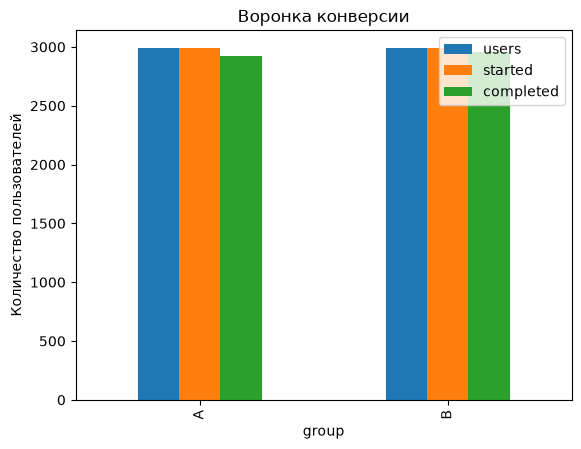

In [188]:
funnel.plot(kind='bar', title='Воронка конверсии')
plt.ylabel('Количество пользователей')
plt.show()

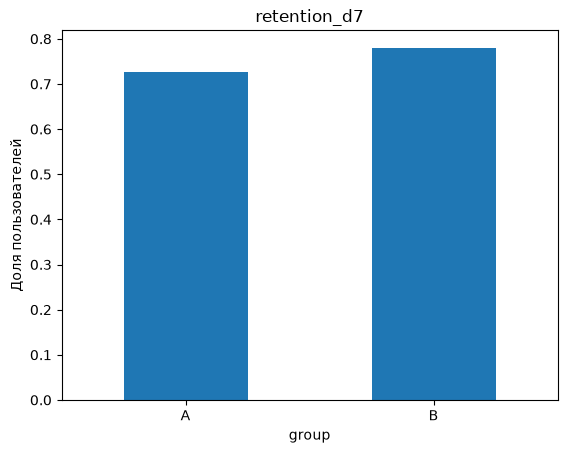

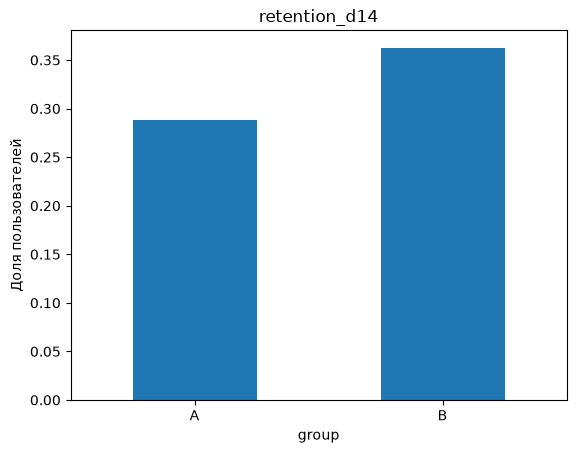

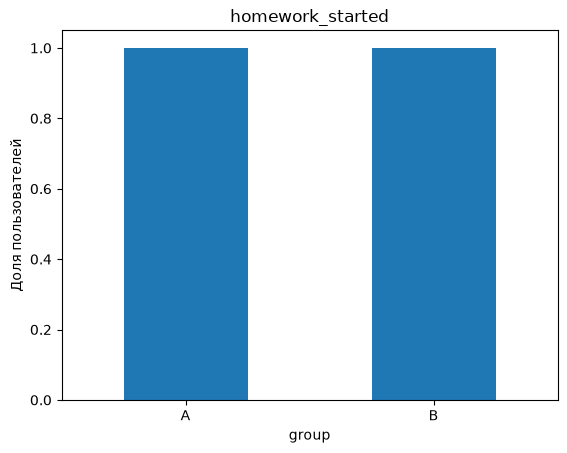

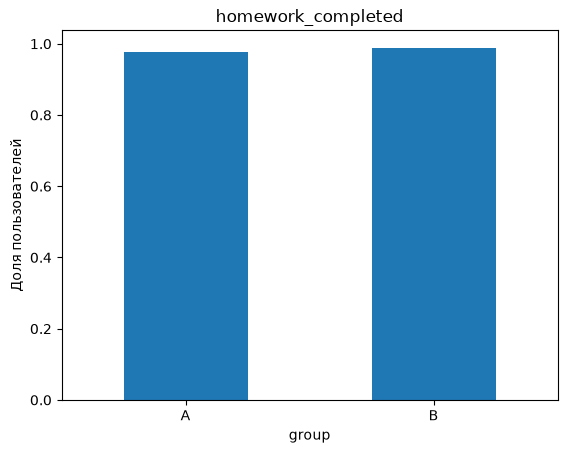

In [152]:
metrics = ['retention_d7', 'retention_d14',
           'homework_started', 'homework_completed']

for metric in metrics:
    user_metrics.groupby('group')[metric].mean().plot(
        kind='bar', title=metric, ylabel='Доля пользователей'
    )
    plt.xticks(rotation=0)
    plt.show()

In [159]:
df[df['event_type'] == 'homework_started'].groupby('group').size()

group
A    30999
B    34109
dtype: int64

In [160]:
user_metrics.groupby('group').agg(
    users=('user_id', 'nunique'),
    started=('homework_started', 'sum'),
    completed=('homework_completed', 'sum')
)

,users,started,completed
group,,,
A,2992,2992,2921
B,2988,2988,2953


In [161]:
events['event_type'].value_counts()

event_type
login                 72396
homework_started      65196
homework_completed    26003
return_visit_d7        4510
return_visit_d14       1945
Name: count, dtype: int64

In [162]:
events.groupby('event_type')['user_id'].nunique()

event_type
homework_completed    5882
homework_started      5988
login                 5988
return_visit_d14      1945
return_visit_d7       4510
Name: user_id, dtype: int64

## Этап 3. Статистические тесты

In [177]:
from statsmodels.stats.proportion import proportions_ztest
import numpy as np
from scipy import stats

test_data = user_metrics.groupby('group').agg(
    users=('user_id', 'nunique'),
    d7=('retention_d7', 'sum'),
    d14=('retention_d14', 'sum'),
    completed=('homework_completed', 'sum')
)

count = test_data['d7'].values
nobs = test_data['users'].values

z_stat, p_value = proportions_ztest(count, nobs)


print('Конверсия d7 тест')
print('Z-statistic:', z_stat)
print('P-value:', p_value)


p1 = count[0]/nobs[0]
p2 = count[1]/nobs[1]
diff = p2 - p1

se = np.sqrt(p1*(1-p1)/nobs[0] + p2*(1-p2)/nobs[1])
z_crit = stats.norm.ppf(0.975)  # 1.96
ci_low = diff - z_crit * se
ci_high = diff + z_crit * se

print(f"Разность конверсий: {diff:.4f} ({diff*100:.2f} п.п.)")
print(f"95% ДИ: [{ci_low:.4f}, {ci_high:.4f}]")

Конверсия d7 тест
Z-statistic: -4.7402488182851945
P-value: 2.1345592456812476e-06
Разность конверсий: 0.0528 (5.28 п.п.)
95% ДИ: [0.0310, 0.0747]


In [179]:
conut_1 = test_data['d14'].values
z_stat, p_value = proportions_ztest(conut_1, nobs)

print('Конверсия d14 тест')
print('Z-statistic:', z_stat)
print('P-value:', p_value)

p1 = conut_1[0]/nobs[0]
p2 = conut_1[1]/nobs[1]
diff = p2 - p1

se = np.sqrt(p1*(1-p1)/nobs[0] + p2*(1-p2)/nobs[1])
z_crit = stats.norm.ppf(0.975)  # 1.96
ci_low = diff - z_crit * se
ci_high = diff + z_crit * se

print(f"Разность конверсий: {diff:.4f} ({diff*100:.2f} п.п.)")
print(f"95% ДИ: [{ci_low:.4f}, {ci_high:.4f}]")


Конверсия d14 тест
Z-statistic: -6.13635589323206
P-value: 8.443588554597712e-10
Разность конверсий: 0.0743 (7.43 п.п.)
95% ДИ: [0.0507, 0.0980]


In [182]:
import numpy as np
from statsmodels.stats.proportion import proportions_ztest
from scipy import stats

groups = test_data.index.tolist()
n1, n2 = test_data['users'].values
c1, c2 = test_data['completed'].values

p1 = c1 / n1
p2 = c2 / n2
diff = p2 - p1

z_stat, p_value = proportions_ztest(
    np.array([c1, c2]), np.array([n1, n2]), alternative='two-sided'
)

se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
z_crit = stats.norm.ppf(0.975)
ci_low = diff - z_crit * se
ci_high = diff + z_crit * se

print('Completed тест')
print(f"Разность конверсий (completed): {diff:.4f} ({diff*100:.2f} п.п.)")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6e}")
print(f"95% ДИ: [{ci_low:.4f}, {ci_high:.4f}]  ({ci_low*100:.2f} – {ci_high*100:.2f} п.п.)")



Completed тест
Разность конверсий (completed): 0.0120 (1.20 п.п.)
Z-statistic: -3.5211
P-value: 4.297772e-04
95% ДИ: [0.0053, 0.0187]  (0.53 – 1.87 п.п.)
